## Logistic Regression With ROC curve and ROC AUC Score

In [19]:
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve,roc_auc_score

from matplotlib import pyplot
import seaborn as sns

In [20]:
X,y = make_classification(n_samples=1000,n_classes=2,random_state=1)

In [21]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42)

In [22]:
## Created a dummy model with all 0
dummy_model_prob = [0 for _ in range(len(y_test))]


In [23]:
model = LogisticRegression()
model.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [24]:
model_prob = model.predict_proba(X_test)
model_prob

array([[1.05252983e-03, 9.98947470e-01],
       [9.03979474e-01, 9.60205260e-02],
       [4.98946536e-01, 5.01053464e-01],
       [1.83435752e-01, 8.16564248e-01],
       [8.99408986e-01, 1.00591014e-01],
       [6.07719750e-01, 3.92280250e-01],
       [1.51824170e-01, 8.48175830e-01],
       [2.86232408e-01, 7.13767592e-01],
       [9.99979912e-02, 9.00002009e-01],
       [1.34810519e-01, 8.65189481e-01],
       [9.99568264e-01, 4.31736109e-04],
       [1.64476111e-01, 8.35523889e-01],
       [8.22873687e-01, 1.77126313e-01],
       [4.60903603e-01, 5.39096397e-01],
       [2.51021785e-01, 7.48978215e-01],
       [1.76733039e-01, 8.23266961e-01],
       [6.04167415e-02, 9.39583258e-01],
       [3.81636590e-01, 6.18363410e-01],
       [8.85148239e-01, 1.14851761e-01],
       [7.38360662e-01, 2.61639338e-01],
       [9.90412932e-01, 9.58706811e-03],
       [5.09267860e-01, 4.90732140e-01],
       [1.06145034e-01, 8.93854966e-01],
       [1.99494399e-03, 9.98005056e-01],
       [8.661823

In [25]:
model_prob = model_prob[:,1]
model_prob

array([9.98947470e-01, 9.60205260e-02, 5.01053464e-01, 8.16564248e-01,
       1.00591014e-01, 3.92280250e-01, 8.48175830e-01, 7.13767592e-01,
       9.00002009e-01, 8.65189481e-01, 4.31736109e-04, 8.35523889e-01,
       1.77126313e-01, 5.39096397e-01, 7.48978215e-01, 8.23266961e-01,
       9.39583258e-01, 6.18363410e-01, 1.14851761e-01, 2.61639338e-01,
       9.58706811e-03, 4.90732140e-01, 8.93854966e-01, 9.98005056e-01,
       1.33817681e-01, 1.26999061e-02, 6.43596359e-01, 9.66536475e-01,
       4.09685637e-02, 2.48605539e-02, 3.61608657e-01, 3.50346898e-02,
       2.29347964e-01, 9.56874850e-01, 5.57425863e-01, 6.52640043e-01,
       1.43477618e-02, 2.74809530e-02, 7.81078622e-01, 2.89121557e-02,
       9.24251909e-01, 8.18368791e-01, 1.38183735e-02, 6.35259639e-04,
       6.97078120e-02, 6.69662619e-02, 9.97883121e-01, 6.63180858e-01,
       8.97529800e-01, 5.78487927e-02, 1.77350184e-02, 3.25047108e-02,
       1.08683348e-01, 5.41863784e-02, 5.47504289e-01, 9.87212922e-01,
      

In [26]:
dummy_model_accu = roc_auc_score(y_test,dummy_model_prob)
model_accu = roc_auc_score(y_test,model_prob)

print(dummy_model_accu)
print(model_accu)

0.5
0.8995383380168608


In [27]:
roc_curve(y_test,dummy_model_prob)

(array([0., 1.]), array([0., 1.]), array([inf,  0.]))

In [28]:
roc_curve(y_test,model_prob)

(array([0.        , 0.        , 0.        , 0.00943396, 0.00943396,
        0.01886792, 0.01886792, 0.02830189, 0.02830189, 0.03773585,
        0.03773585, 0.04716981, 0.04716981, 0.05660377, 0.05660377,
        0.06603774, 0.06603774, 0.0754717 , 0.0754717 , 0.08490566,
        0.08490566, 0.09433962, 0.09433962, 0.10377358, 0.10377358,
        0.12264151, 0.12264151, 0.13207547, 0.13207547, 0.14150943,
        0.14150943, 0.16981132, 0.16981132, 0.17924528, 0.17924528,
        0.18867925, 0.18867925, 0.19811321, 0.19811321, 0.21698113,
        0.21698113, 0.22641509, 0.22641509, 0.23584906, 0.23584906,
        0.24528302, 0.24528302, 0.25471698, 0.25471698, 0.32075472,
        0.32075472, 0.33018868, 0.33018868, 0.39622642, 0.39622642,
        0.4245283 , 0.4245283 , 0.54716981, 0.54716981, 0.55660377,
        0.55660377, 0.60377358, 0.60377358, 1.        ]),
 array([0.        , 0.0106383 , 0.22340426, 0.22340426, 0.27659574,
        0.27659574, 0.35106383, 0.35106383, 0.36170213, 0.

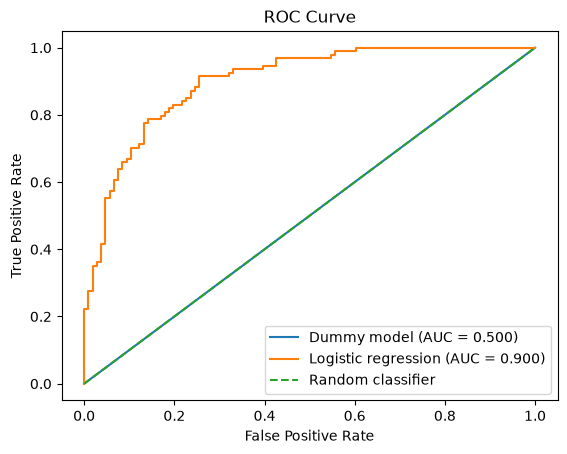

In [30]:
dummy_fpr, dummy_tpr, dummy_threshold = roc_curve(y_test, dummy_model_prob)
model_fpr, model_tpr, model_threshold = roc_curve(y_test, model_prob)

pyplot.plot(dummy_fpr, dummy_tpr, label=f"Dummy model (AUC = {dummy_model_accu:.3f})")
pyplot.plot(model_fpr, model_tpr, label=f"Logistic regression (AUC = {model_accu:.3f})")
pyplot.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
pyplot.xlabel("False Positive Rate")
pyplot.ylabel("True Positive Rate")
pyplot.title("ROC Curve")
pyplot.legend()
pyplot.show()

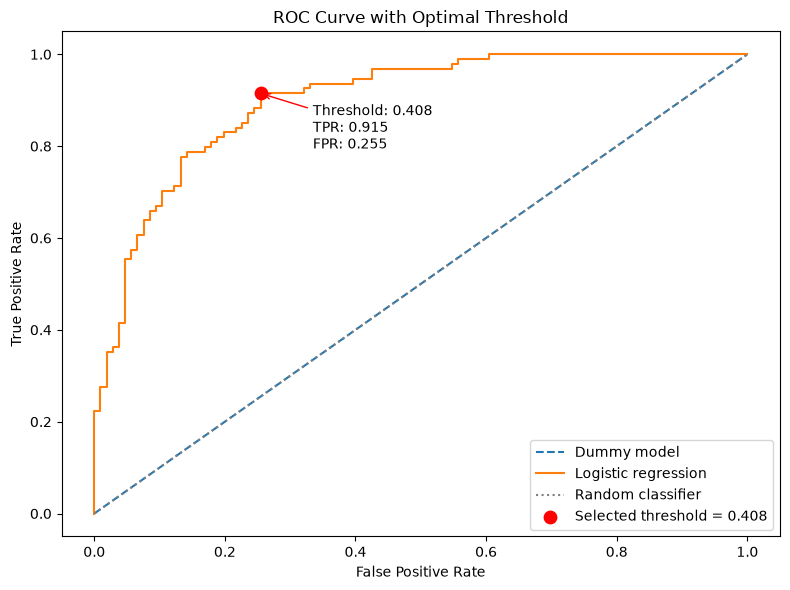

Selected threshold: 0.408


In [31]:
import numpy as np

# Choose the threshold that maximizes TPR - FPR (Youden's J statistic).
youden_j = model_tpr - model_fpr
best_index = np.argmax(youden_j)
best_threshold = model_threshold[best_index]

fig, ax = pyplot.subplots(figsize=(8, 6))
ax.plot(dummy_fpr, dummy_tpr, linestyle="--", label="Dummy model")
ax.plot(model_fpr, model_tpr, label="Logistic regression")
ax.plot([0, 1], [0, 1], linestyle=":", color="gray", label="Random classifier")
ax.scatter(
    model_fpr[best_index],
    model_tpr[best_index],
    color="red",
    s=80,
    zorder=3,
    label=f"Selected threshold = {best_threshold:.3f}",
)

ax.annotate(
    f"Threshold: {best_threshold:.3f}\nTPR: {model_tpr[best_index]:.3f}\nFPR: {model_fpr[best_index]:.3f}",
    xy=(model_fpr[best_index], model_tpr[best_index]),
    xytext=(model_fpr[best_index] + 0.08, model_tpr[best_index] - 0.12),
    arrowprops={"arrowstyle": "->", "color": "red"},
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve with Optimal Threshold")
ax.legend(loc="lower right")
pyplot.tight_layout()
pyplot.show()

print(f"Selected threshold: {best_threshold:.3f}")